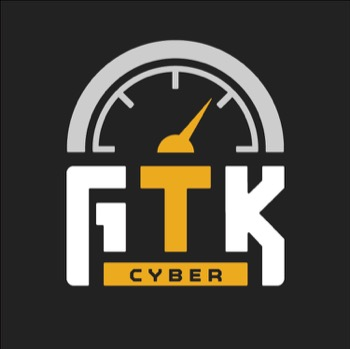


# Worksheet 1.1:  Vectorized Data Structures
This worksheet covers concepts covered in Module 1 - Vectorized Data Structures.  It should take no more than 20-30 minutes to complete.  Please raise your hand if you get stuck.

You may of course use AI to generate answers, but we would **strongly** encourage you to make sure you are familiar with the concepts presented in this module as they are core foundational concepts for both machine learning and artificial intelligence.

There are many ways to accomplish the tasks that you are presented with, however you will find that by using the techniques covered in class, the exercises should be relatively simple.

## Import the Libraries
For this exercise, we will be using:
* Pandas (http://pandas.pydata.org/pandas-docs/stable/)
* ipaddress (https://docs.python.org/3/library/ipaddress.html)
* apachelogs (https://pypi.org/project/apachelogs/)
* user_agents (https://pypi.org/project/user-agents/)

In [ ]:
# --- data-loader (local files / Databricks volume) ---
import os
import tempfile
try:
    dbutils  # defined only on Databricks
    DATA_HOME = os.environ.get("COURSE_DATA_HOME", "/Volumes/ai_cyber_bootcamp/course/data/")
    WORK_HOME = os.path.abspath("../work") + "/"
    SCRATCH_HOME = tempfile.gettempdir()
    ON_DATABRICKS = True
except NameError:
    DATA_HOME = "../data/"
    WORK_HOME = DATA_HOME
    SCRATCH_HOME = WORK_HOME
    ON_DATABRICKS = False
os.makedirs(WORK_HOME, exist_ok=True)

def handoff(name):
    """Output of an earlier worksheet: the student's own copy if it exists, else the shipped one."""
    p = WORK_HOME + name
    return p if os.path.exists(p) else DATA_HOME + name
# --- end data-loader ---


In [ ]:
import pandas as pd
from ipaddress import ip_address

# Set the `DATA_HOME` Variable
All the labs will be using various data files from this repository.  If you cloned the repository to your local machine, you shouldn't have to change this variable.  If not, you will need to change it to the path where you downloaded the class data files.

In [ ]:
# DATA_HOME comes from the data-loader cell at the top of this notebook

## Exercise 1:  Splitting and Filtering a Series

In this exercise, you are given a list of email addresses called `emails`.  Your goal is to find the email accounts from domains that end in `.edu`.  To accomplish this, you will need to:
1. Filter the series to remove the emails that do not end in .edu
2. Extract the accounts.

If you get stuck, refer to the documentation for Pandas string manipulation (https://pandas.pydata.org/pandas-docs/stable/user_guide/text.html) or the slides.  Note that there are various functions to accomplish this task.

In [ ]:
emails = ['alawrence0@prlog.org',
'blynch1@businessweek.com',
'mdixon2@cmu.edu',
'rvasquez3@1688.com',
'astone4@creativecommons.org',
'mcarter5@chicagotribune.com',
'dcole6@vinaora.com',
'kpeterson7@topsy.com',
'ewebb8@cnet.com',
'jtaylor9@google.ru',
'ecarra@buzzfeed.com',
'jjonesb@arizona.edu',
'jbowmanc@disqus.com',
'eduardo_sanchezd@npr.org',
'emooree@prweb.com',
'abbedu@google.com',
'eberryf@brandeis.edu',
'sgardnerh@wikipedia.org',
'balvarezi@delicious.com',
'blewisj@privacy.gov.au']

In [ ]:
# Your code here...

## Exercise 2: Manipulating a Series

You are given a Series of IP Addresses and the goal is to limit this data to private IP addresses.  Python has an `ipaddress` module which provides the capability to create, manipulate and operate on IPv4 and IPv6 addresses and networks.  Complete documentation is available here: https://docs.python.org/3/library/ipaddress.html.

Here are some examples of how you might use this module:

```python
myIP = ipaddress.ip_address( '192.168.0.1' )
myNetwork = ipaddress.ip_network( '192.168.0.0/28' )

#Check membership in network
if myIP in myNetwork:  #This works
    print( "Yay!" )

#Loop through CIDR blocks
for ip in myNetwork:
    print( ip )

192.168.0.0
192.168.0.1
…
…
192.168.0.13
192.168.0.14
192.168.0.15

#Testing to see if an IP is private
if myIP.is_private:
    print( "This IP is private" )
else:
    print( "Routable IP" )

```

1.  First, write a function which takes an IP address and returns true if the IP is private, false if it is public.  HINT:  use the ```ipaddress``` module.
2.  Next, use this to create a Series of true/false values in the same sequence as your original Series.
3.  Finally, use this to filter out the original Series so that it contains only private IP addresses.

In [ ]:
hosts = [ '192.168.1.2', '10.10.10.2', '172.143.23.34', '34.34.35.34', '172.15.0.1', '172.17.0.1']

In [ ]:
# Your code here ...

## Exercise 3:
You have been given a list of US phone numbers.  The area code is the first three digits.  Your task is to produce a summary of how many times each area code appears in the list. To do this you will need to:
1. Extract the area code from each phone number
2. Count the unique occurrences.

In [ ]:
phone_numbers = [
'(833) 759-6854',
'(811) 268-9951',
'(855) 449-4648',
'(833) 212-2929',
'(833) 893-7475',
'(822) 346-3086',
'(844) 259-9074',
'(855) 975-8945',
'(811) 385-8515',
'(811) 523-5090',
'(844) 593-5677',
'(833) 534-5793',
'(899) 898-3043',
'(833) 662-7621',
'(899) 146-8244',
'(822) 793-4965',
'(822) 641-7853',
'(833) 153-7848',
'(811) 958-2930',
'(822) 332-3070',
'(833) 223-1776',
'(811) 397-1451',
'(844) 096-0377',
'(822) 000-0717',
'(899) 311-1880']

In [ ]:
# Your code here ...  (Don't forget to read the data into a Series)

# Part 2:  DataFrames
This next part of the lab will focus on working with two dimensional data, also known as dataframes.  Most security data should be mapped to 2D tables, so this section is vital to understanding how to access security data sets.  These exercises will walk you through the process of getting data into a dataframe and then manipulating that data.

## Exercise 4:
In the data file, there is a webserver file called `hackers-access.httpd`.  For this exercise, you will use this file to answer the following questions:
1.  Which browsers are the top 3 most used browsers in this data?
2.  Which are the least (3) used operating systems?

In order to accomplish this task, do the following:
1. Parse each log to pull out the following relevant information
        - user agent, bytes, status, remote host, number of bytes sent
2. For each log, store the raw text and each piece of information in a data frame
3.  Write a function which takes a User Agent string as an argument and returns the name of the operating system and the browser family.  HINT:  You might want to use `user_agents` module, the documentation for which is available here: (https://pypi.python.org/pypi/user-agents)
4.  Next, apply this function to the column which contains the user agent string
5.  Store this series as a new column in the dataframe
6.  Count the occurrences of each value in the new columns (top 5 is fine)

First we need to grab another Python library with pip
[https://pypi.org/project/apachelogs/](https://pypi.org/project/apachelogs/)

In [ ]:
# apachelogs ships with the course environment (cluster library on Databricks)

We will take a look at how to parse a single log. 

In [ ]:
raw_text_log = '192.161.57.88 - - [30/Oct/2015:15:59:39 +0100] "POST /login_form HTTP/1.1" 200 18354 "http://niels.basjes.nl/login_form" "Mozilla/5.0 (Windows NT 6.1; rv:32.0) Gecko/20100101 Firefox/32.0"'
raw_text_log

In [ ]:
from apachelogs import LogParser

# Instatiate with a log format string
line_parser = LogParser("%h %l %u %t \"%r\" %>s %b \"%{Referer}i\" \"%{User-agent}i\"")

# create a dictionary to hold the result of the parse method
log_dict = {}
log_dict = line_parser.parse(raw_text_log)

# to see the raw text from the log, use the entry method
log_dict.entry

What other kinds of items can you pull out of this log with the methods in this class? Remember you can type <log_dict.> and hit tab to see your options, OR go to the documentation for the apachelogs library (listed above)

In [ ]:
# Step 1:
# pull out the user agent string needed for 
log_dict.headers_in["User-agent"]

Now we will import the logs from a file, parse each one and store the information in a dataframe

In [ ]:
# Step 2: 
#Read in the log file
server_log = open(DATA_HOME + "hackers-access.httpd", "r")

#Create an empty dataframe
parsed_server_data = <YOUR CODE>

# read and parse each line and store the information in the columns of the dataframe
for num, line in enumerate(server_log):
    data = {}
    data = line_parser.parse(<YOUR CODE>)
    parsed_server_data.loc[num,'raw_log']= <YOUR CODE>
    parsed_server_data.loc[num,'remote_host']= <YOUR CODE>
    parsed_server_data.loc[num,'user_agent'] = <YOUR CODE>
    parsed_server_data.loc[num,'request_time']= <YOUR CODE>
    parsed_server_data.loc[num,'status']= <YOUR CODE>
    parsed_server_data.loc[num,'bytes'] = <YOUR CODE>

# view the first 5 rows
parsed_server_data.<YOUR CODE>

Install the user_agents library

In [ ]:
# ua-parser and user-agents ship with the course environment (cluster libraries on Databricks)

In [ ]:
# Step 3: Fix the functions to parse os and family from the user_agent column
from user_agents import parse

def get_os(x):
    user_agent_os = parse(x)
    return user_agent_os

def get_browser(x):
    user_agent_browser = parse(x).browser
    return user_agent_browser

In [ ]:
# Step 4-5: Apply the functions to the dataframe

parsed_server_data['os'] = 
parsed_server_data['browser'] = 

In [ ]:
# Step 6: Count the ocurrences of each unique value in the 2 new columns

### YOUR CODE ###

In [ ]:
# Question 1 Answer

### YOUR CODE ###


In [ ]:
# Question 2 Answer

### YOUR CODE ###

# Putting it All Together:  Data Analysis
In this next section, you will be using Pandas to answer some analytic questions from a dataset.

Using the `dailybots.csv` file, read the file (found in the `data` directory) into a DataFrame and perform the following operation:
1.  Filter the DataFrame to include bots from the Government/Politics Industry.


In [ ]:
# Your code here...

## Exercise 5: Which industry sees the most Ramnit infections? Least?

Count the number of infected days for "Ramnit" in each industry.
How:
1.  First filter the data to remove all the infections we don't care about
2.  Aggregate the data on the column of interest. HINT:  You might want to use the `groupby()` function (http://pandas.pydata.org/pandas-docs/stable/groupby.html)
3.  Add up the results

In [ ]:
# Your code here ...

# Exercise 6: Calculate the min, max, median and mean infected orgs for each bot family, sort by median
In this exercise, you are asked to calculate the min, max, median and mean of infected orgs for each bot family sorted by median.
1.  Using the `groupby()` function, create a grouped data frame
2.  You can do this one metric at a time OR you can use the .agg() function. You might want to refer to the documentation here:  http://pandas.pydata.org/pandas-docs/stable/groupby.html#applying-multiple-functions-at-once
3.  Sort the values (HINT HINT) by the median column

In [ ]:
# Your code here ...

# Exercise 7: Which date had the total most bot infections and how many infections on that day?
In this exercise you are asked to aggregate and sum the number of infections (hosts) by date.  Once you've done that, the next step is to sort in descending order.

In [ ]:
# Your code here ...